# A2: Predicting Car Price II (Linear Regression from scratch + MLflow)

We reuse the A1 cleaning and preprocessing, then replace the sklearn models with our own
`LinearRegression` class (from *03 - Regularization.ipynb*) extended with:

1. `r2()` score
2. `zeros` or `xavier` weight initialisation
3. momentum
4. `plot_feature_importance()`

and run a cross-validated experiment over regression type × momentum × GD method × init × learning
rate, tracked in **MLflow**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, os, itertools, warnings
warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED)

## 1. Data cleaning (same rules as A1)

In [2]:
df = pd.read_csv('cars.csv')

owner_map = {'First Owner': 1, 'Second Owner': 2, 'Third Owner': 3,
             'Fourth & Above Owner': 4, 'Test Drive Car': 5}
df['owner'] = df['owner'].map(owner_map)
df = df[~df['fuel'].isin(['CNG', 'LPG'])]                       # different mileage unit (km/kg)
df['mileage'] = df['mileage'].str.split(' ').str[0].astype(float)  # "23.4 kmpl" -> 23.4
df['engine'] = df['engine'].str.split(' ').str[0].astype(float)    # "1248 CC"   -> 1248
df['max_power'] = pd.to_numeric(df['max_power'].str.split(' ').str[0], errors='coerce')  # "74 bhp" -> 74
df['brand'] = df['name'].str.split(' ').str[0]                   # first word of the name
df = df.drop(columns=['name', 'torque'])
df = df[df['owner'] != 5].reset_index(drop=True)                 # drop Test Drive Cars
print(df.shape)

(8028, 12)


## 2. Split, impute, encode, scale (statistics from the training set only)

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop(columns=['selling_price'])
y = np.log(df['selling_price'])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)

num_cols = ['year', 'km_driven', 'owner', 'mileage', 'engine', 'max_power', 'seats']
cat_cols = ['fuel', 'seller_type', 'transmission', 'brand']

fill_values = {c: X_train[c].median() for c in num_cols}
fill_values['seats'] = X_train['seats'].mode()[0]
fill_values.update({c: X_train[c].mode()[0] for c in cat_cols})
X_train, X_test = X_train.fillna(fill_values), X_test.fillna(fill_values)

X_train_enc = pd.get_dummies(X_train, columns=cat_cols, drop_first=True, dtype=int)
X_test_enc = pd.get_dummies(X_test, columns=cat_cols, drop_first=True, dtype=int)
X_train_enc, X_test_enc = X_train_enc.align(X_test_enc, join='left', axis=1, fill_value=0)

# Scaling matters even more now: gradient descent converges badly when features have different scales
scaler = StandardScaler()
X_train_enc[num_cols] = scaler.fit_transform(X_train_enc[num_cols])
X_test_enc[num_cols] = scaler.transform(X_test_enc[num_cols])

feature_names = list(X_train_enc.columns)
num_idx = [feature_names.index(c) for c in num_cols]   # used by PolynomialRegression
X_tr, y_tr = X_train_enc.values.astype(float), y_train.values
X_te, y_te = X_test_enc.values.astype(float), y_test.values
print(X_tr.shape, X_te.shape)

(6422, 40) (1606, 40)


## 3. The `LinearRegression` class

The class lives in `linear_regression.py` (written by the cell below) so the web app can import
the same code to load the saved model. Reading notes:

- **r2**: `1 - SS_res / SS_tot`, the share of the variance of y the model explains.
- **Xavier init**: weights drawn from `U[-1/sqrt(m), 1/sqrt(m)]` with m inputs, so starting
  predictions are small but not all identical.
- **Momentum**: each update adds `momentum × previous step`, so the parameters keep rolling in a
  consistent direction (faster) and opposite gradients cancel (less zig-zag).
- **Methods**: `batch` uses all rows per update, `mini` uses 64 rows, `sto` uses 1 row.
- **Early stopping**: training ends when the validation MSE has not improved for 20 epochs, or
  immediately when it explodes (a learning rate that is too large).
- **Polynomial**: adds squares and pairwise products of the 7 numeric columns.

In [4]:
%%writefile linear_regression.py
"""Linear Regression from scratch (based on the class notebook 03 - Regularization.ipynb).

Additions for A2:
  * r2()                    - coefficient of determination
  * init='zeros'|'xavier'   - weight initialisation
  * momentum                - gradient descent with momentum (0 = off)
  * plot_feature_importance - bar chart of the coefficients
  * PolynomialRegression    - degree-2 feature expansion before fitting
"""
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures, StandardScaler


# ---------------- penalties ----------------
class NoPenalty:
    """Plain linear regression: no penalty."""
    def __call__(self, theta):
        return 0.0

    def derivation(self, theta):
        return np.zeros_like(theta)


class LassoPenalty:
    """L1 penalty: l * sum(|theta|). Pushes small coefficients to exactly zero."""
    def __init__(self, l):
        self.l = l

    def __call__(self, theta):
        return self.l * np.sum(np.abs(theta))

    def derivation(self, theta):
        return self.l * np.sign(theta)


class RidgePenalty:
    """L2 penalty: l * sum(theta^2). Shrinks all coefficients smoothly."""
    def __init__(self, l):
        self.l = l

    def __call__(self, theta):
        return self.l * np.sum(np.square(theta))

    def derivation(self, theta):
        return self.l * 2 * theta


# ---------------- model ----------------
class LinearRegression:
    def __init__(self, regularization=None, lr=0.001, method='batch', init='zeros',
                 momentum=0.0, num_epochs=1000, batch_size=64, patience=20, tol=1e-6, seed=42):
        """
        regularization : penalty object (NoPenalty / LassoPenalty / RidgePenalty), None = no penalty
        lr             : learning rate (step size)
        method         : 'batch' (all rows per step), 'mini' (batch_size rows), 'sto' (1 row)
        init           : 'zeros' or 'xavier'
        momentum       : 0 turns momentum off; a value in (0, 1) turns it on
        num_epochs     : maximum passes over the training data
        patience, tol  : early stopping - stop when the loss has not improved by tol for patience epochs
        """
        assert method in ('batch', 'mini', 'sto')
        assert init in ('zeros', 'xavier')
        assert 0 <= momentum < 1
        self.regularization = regularization or NoPenalty()
        self.lr, self.method, self.init = lr, method, init
        self.momentum, self.num_epochs, self.batch_size = momentum, num_epochs, batch_size
        self.patience, self.tol, self.seed = patience, tol, seed

    # ---- metrics ----
    @staticmethod
    def mse(ytrue, ypred):
        return np.mean((ytrue - ypred) ** 2)

    @staticmethod
    def r2(ytrue, ypred):
        """R^2 = 1 - SS_res / SS_tot : share of the variance of y explained by the model."""
        ss_res = np.sum((ytrue - ypred) ** 2)
        ss_tot = np.sum((ytrue - np.mean(ytrue)) ** 2)
        return 1 - ss_res / ss_tot

    # ---- helpers ----
    def _transform(self, X):
        """Feature transform before the bias column. Overridden by PolynomialRegression."""
        return X

    def _add_bias(self, X):
        X = self._transform(np.asarray(X, dtype=float))
        return np.hstack([np.ones((X.shape[0], 1)), X])

    def _init_theta(self, n_features, rng):
        if self.init == 'zeros':
            return np.zeros(n_features)
        # Xavier: uniform in [-1/sqrt(m), 1/sqrt(m)], m = number of inputs
        m = n_features
        lower, upper = -1.0 / np.sqrt(m), 1.0 / np.sqrt(m)
        return lower + rng.random(n_features) * (upper - lower)

    def _gradient(self, X, y):
        error = X @ self.theta - y
        grad = X.T @ error / X.shape[0]
        reg = self.regularization.derivation(self.theta)
        reg[0] = 0  # never penalise the bias term
        return grad + reg

    def _step(self, grad):
        """One parameter update, with optional momentum.

        The brief's pseudocode writes `theta - step + momentum * prev_step`; with prev_step being a
        positive step that would *undo* part of the previous move. The standard (heavy-ball) form
        keeps moving in the previous direction: theta = theta - (step + momentum * prev_step).
        """
        step = self.lr * grad + self.momentum * self.prev_step
        self.theta = self.theta - step
        self.prev_step = step

    # ---- training ----
    def fit(self, X, y, X_val=None, y_val=None):
        rng = np.random.default_rng(self.seed)
        X, y = self._add_bias(X), np.asarray(y, dtype=float)
        has_val = X_val is not None
        if has_val:
            X_val, y_val = self._add_bias(X_val), np.asarray(y_val, dtype=float)

        self.theta = self._init_theta(X.shape[1], rng)
        self.prev_step = np.zeros_like(self.theta)
        self.history, self.diverged = [], False
        best, wait = np.inf, 0
        bs = {'batch': X.shape[0], 'mini': self.batch_size, 'sto': 1}[self.method]

        for epoch in range(self.num_epochs):
            # shuffle every epoch so mini-batches / single samples are in a new random order
            idx = rng.permutation(X.shape[0]) if self.method != 'batch' else np.arange(X.shape[0])
            for start in range(0, X.shape[0], bs):
                b = idx[start:start + bs]
                self._step(self._gradient(X[b], y[b]))

            # monitor the validation loss (or training loss when there is no validation set)
            Xm, ym = (X_val, y_val) if has_val else (X, y)
            with np.errstate(over='ignore', invalid='ignore'):
                loss = self.mse(ym, Xm @ self.theta)
            self.history.append(loss)
            if not np.isfinite(loss) or loss > 1e10:  # learning rate too large -> exploded
                self.diverged = True
                break
            if loss < best - self.tol:
                best, wait = loss, 0
            else:
                wait += 1
                if wait >= self.patience:
                    break
        return self

    def predict(self, X):
        return self._add_bias(X) @ self.theta

    # ---- interpretation ----
    def _coef(self):
        return self.theta[1:]  # drop the bias

    def plot_feature_importance(self, feature_names, top=15, ax=None):
        """Bar chart of |coefficient| per feature. Only meaningful because inputs are standardised."""
        coef = self._coef()
        order = np.argsort(np.abs(coef))[-top:]
        ax = ax or plt.subplots(figsize=(8, 0.4 * len(order) + 1))[1]
        colors = ['tab:green' if c > 0 else 'tab:red' for c in coef[order]]
        ax.barh(np.array(feature_names)[order], np.abs(coef[order]), color=colors)
        ax.set_xlabel('|coefficient|  (green = raises price, red = lowers price)')
        ax.set_title('Feature importance')
        return ax


class NormalRegression(LinearRegression):
    def __init__(self, **kw):
        super().__init__(regularization=NoPenalty(), **kw)


class LassoRegression(LinearRegression):
    def __init__(self, l=0.01, **kw):
        super().__init__(regularization=LassoPenalty(l), **kw)


class RidgeRegression(LinearRegression):
    def __init__(self, l=0.01, **kw):
        super().__init__(regularization=RidgePenalty(l), **kw)


class PolynomialRegression(LinearRegression):
    """Adds degree-2 terms (x_i^2 and x_i*x_j) so a linear model can fit curves.

    poly_idx : column positions to expand (we pass the numeric columns). Expanding the one-hot
               dummies too would create ~800 mostly-empty columns (e.g. brand_BMW * brand_Audi = 0).
    The new terms are standardised: squaring an already-large value (a car with 2M km is ~30 std
    devs out, squared ~900) makes gradient descent explode otherwise.
    """
    def __init__(self, degree=2, poly_idx=None, **kw):
        super().__init__(regularization=NoPenalty(), **kw)
        self.poly = PolynomialFeatures(degree=degree, include_bias=False)
        self.poly_scaler = StandardScaler()
        self.poly_idx = poly_idx
        self._poly_fitted = False

    def _transform(self, X):
        idx = self.poly_idx if self.poly_idx is not None else list(range(X.shape[1]))
        self._n_in = len(idx)
        if not self._poly_fitted:  # fitted once, on the training data passed to the first fit()
            self.poly.fit(X[:, idx])
            self.poly_scaler.fit(self.poly.transform(X[:, idx])[:, self._n_in:])
            self._poly_fitted = True
        # the first n_in poly columns are the original features (already in X) -> keep only new terms
        extra = self.poly.transform(X[:, idx])[:, self._n_in:]
        return np.hstack([X, self.poly_scaler.transform(extra)])

    def plot_feature_importance(self, feature_names, top=15, ax=None):
        idx = self.poly_idx if self.poly_idx is not None else list(range(len(feature_names)))
        extra = self.poly.get_feature_names_out(np.array(feature_names)[idx])[self._n_in:]
        return super().plot_feature_importance(list(feature_names) + list(extra), top, ax)

Overwriting linear_regression.py


In [5]:
from linear_regression import (LinearRegression, NormalRegression, LassoRegression,
                               RidgeRegression, PolynomialRegression)

# quick check that our r2 matches sklearn's
from sklearn.metrics import r2_score
a, b = np.array([3., 5., 7., 9.]), np.array([2.5, 5.5, 6.5, 9.5])
print(LinearRegression.r2(a, b), r2_score(a, b))

0.95 0.95


## 4. Experiment with MLflow

For each of the 4 × 2 × 3 × 2 × 3 = **144 combinations** we run 3-fold cross-validation on the
training set and log the mean MSE and R² to MLflow (`mlflow.db`). Ridge and Lasso use λ = 0.01.
The runs are computed in parallel and then logged one by one.

In [6]:
from sklearn.model_selection import KFold
from joblib import Parallel, delayed

def make_model(reg, **kw):
    if reg == 'Normal':     return NormalRegression(**kw)
    if reg == 'Lasso':      return LassoRegression(l=0.01, **kw)
    if reg == 'Ridge':      return RidgeRegression(l=0.01, **kw)
    if reg == 'Polynomial': return PolynomialRegression(degree=2, poly_idx=num_idx, **kw)

grid = {
    'regression': ['Normal', 'Lasso', 'Ridge', 'Polynomial'],
    'momentum': [0.0, 0.9],                 # 0 = without momentum
    'method': ['sto', 'mini', 'batch'],
    'init': ['zeros', 'xavier'],
    'lr': [0.01, 0.001, 0.0001],
}
configs = [dict(zip(grid, v)) for v in itertools.product(*grid.values())]
kfold = KFold(n_splits=3, shuffle=True, random_state=SEED)

def cross_validate(cfg):
    mses, r2s, epochs, diverged = [], [], [], False
    for tr, va in kfold.split(X_tr):
        reg = cfg['regression']
        m = make_model(reg, lr=cfg['lr'], method=cfg['method'], init=cfg['init'], momentum=cfg['momentum'])
        m.fit(X_tr[tr], y_tr[tr], X_tr[va], y_tr[va])
        if m.diverged:
            diverged = True
            break
        p = m.predict(X_tr[va])
        mses.append(m.mse(y_tr[va], p)); r2s.append(m.r2(y_tr[va], p)); epochs.append(len(m.history))
    return {**cfg, 'diverged': diverged,
            'cv_mse': np.nan if diverged else np.mean(mses),
            'cv_r2': np.nan if diverged else np.mean(r2s),
            'epochs': np.nan if diverged else np.mean(epochs)}

results = Parallel(n_jobs=-1)(delayed(cross_validate)(c) for c in configs)
results = pd.DataFrame(results)
print(len(results), 'runs,', results['diverged'].sum(), 'diverged')

144 runs, 12 diverged


In [7]:
import mlflow
mlflow.set_tracking_uri('sqlite:///mlflow.db')
mlflow.set_experiment('A2-car-price')

for r in results.to_dict('records'):
    name = f"{r['regression']}-{r['method']}-{r['init']}-lr{r['lr']}-mom{r['momentum']}"
    with mlflow.start_run(run_name=name):
        mlflow.log_params({k: r[k] for k in grid})
        mlflow.set_tag('diverged', r['diverged'])
        if not r['diverged']:
            mlflow.log_metrics({'cv_mse': r['cv_mse'], 'cv_r2': r['cv_r2'], 'epochs': r['epochs']})
print('logged', len(results), 'runs to mlflow.db  ->  view with:  mlflow ui --backend-store-uri sqlite:///mlflow.db')

2026/10/25 15:21:22 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/25 15:21:22 INFO mlflow.store.db.utils: Updating database tables
2026/10/25 15:21:25 INFO mlflow.tracking.fluent: Experiment with name 'A2-car-price' does not exist. Creating a new experiment.


logged 144 runs to mlflow.db  ->  view with:  mlflow ui --backend-store-uri sqlite:///mlflow.db


In [9]:
# !mlflow ui --backend-store-uri sqlite:///mlflow.db

### MLflow screenshots

All runs, sorted by `cv_mse`:

![MLflow runs](screenshots/mlflow_run_cv_mse.png)

Comparing the top runs:

![MLflow chart](screenshots/mlflow_charts.png)

## 5. Results

In [10]:
# Final comparison table: best 15 configurations
ok = results[~results['diverged']].sort_values('cv_mse')
ok.head(15).round(4)

,regression,momentum,method,init,lr,diverged,cv_mse,cv_r2,epochs
114,Polynomial,0.0,mini,zeros,0.0100,False,0.0606,0.9133,666.0000
117,Polynomial,0.0,mini,xavier,0.0100,False,0.0608,0.9129,641.6667
133,Polynomial,0.9,mini,zeros,0.0010,False,0.0609,0.9129,591.0000
136,Polynomial,0.9,mini,xavier,0.0010,False,0.0611,0.9126,591.0000
110,Polynomial,0.0,sto,zeros,0.0001,False,0.0618,0.9116,799.0000
113,Polynomial,0.0,sto,xavier,0.0001,False,0.0620,0.9113,799.0000
27,Normal,0.9,mini,xavier,0.0100,False,0.0684,0.9020,121.0000
4,Normal,0.0,sto,xavier,0.0010,False,0.0687,0.9017,180.6667
23,Normal,0.9,sto,xavier,0.0001,False,0.0688,0.9016,180.6667
6,Normal,0.0,mini,zeros,0.0100,False,0.0693,0.9008,645.3333


In [11]:
# Average over everything else, to see the effect of each choice on its own
# (diverged runs are counted as failures, so the table also shows how often each option breaks)
summary = []
for col in grid:
    # median, not mean: a few runs that barely trained (R² of -80) would swamp a mean
    g = results.groupby(col).agg(median_cv_r2=('cv_r2', 'median'), best_cv_r2=('cv_r2', 'max'),
                                 diverged_runs=('diverged', 'sum'))
    g.index = [f'{col} = {i}' for i in g.index]
    summary.append(g)
pd.concat(summary).round(3)

,median_cv_r2,best_cv_r2,diverged_runs
regression = Lasso,0.851,0.882,0
regression = Normal,0.817,0.902,0
regression = Polynomial,-0.393,0.913,12
regression = Ridge,0.862,0.895,0
momentum = 0.0,0.758,0.913,4
momentum = 0.9,0.872,0.913,8
method = batch,-3.838,0.890,0
method = mini,0.862,0.913,2
method = sto,0.882,0.912,10
init = xavier,0.817,0.913,6


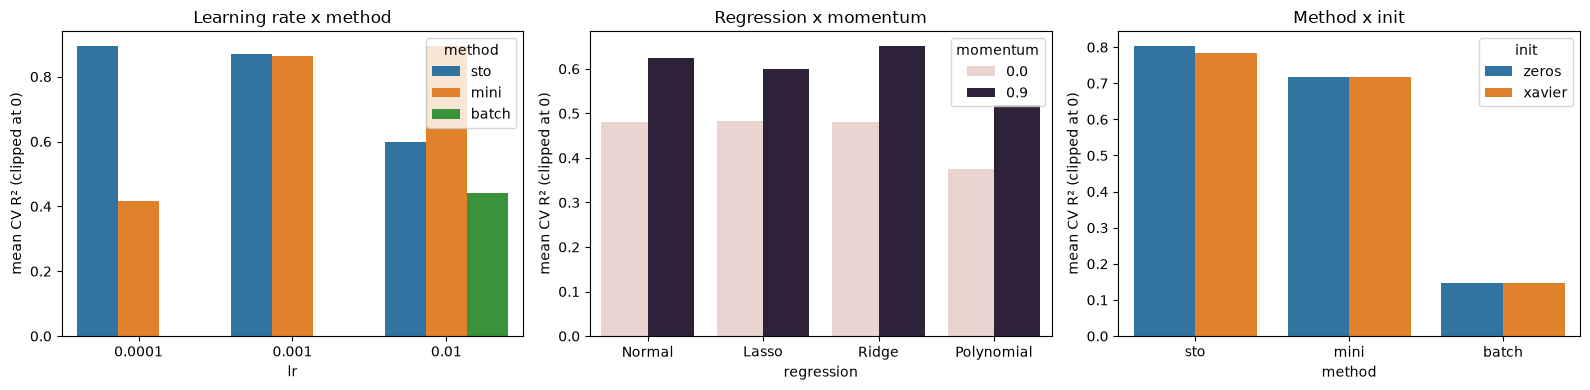

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
plot_df = results.copy()
plot_df['cv_r2'] = plot_df['cv_r2'].clip(lower=0)       # very bad / diverged runs shown as 0
sns.barplot(data=plot_df, x='lr', y='cv_r2', hue='method', ax=ax[0], errorbar=None).set_title('Learning rate x method')
sns.barplot(data=plot_df, x='regression', y='cv_r2', hue='momentum', ax=ax[1], errorbar=None).set_title('Regression x momentum')
sns.barplot(data=plot_df, x='method', y='cv_r2', hue='init', ax=ax[2], errorbar=None).set_title('Method x init')
for a in ax: a.set_ylabel('mean CV R² (clipped at 0)')
plt.tight_layout(); plt.show()

## 6. Best model on the test set

In [13]:
best = ok.iloc[0].to_dict()
print('best configuration:', {k: best[k] for k in grid})

# Retrain on the whole training set. A 10% slice is held out only to decide when to stop training.
X_fit, X_stop, y_fit, y_stop = train_test_split(X_tr, y_tr, test_size=0.1, random_state=SEED)
best_model = make_model(best['regression'], lr=best['lr'], method=best['method'],
                        init=best['init'], momentum=best['momentum'])
best_model.fit(X_fit, y_fit, X_stop, y_stop)

pred = best_model.predict(X_te)
print(f'Test MSE (log price): {best_model.mse(y_te, pred):.4f}')
print(f'Test R2  (log price): {best_model.r2(y_te, pred):.4f}')
print(f'Test R2  (price)    : {best_model.r2(np.exp(y_te), np.exp(pred)):.4f}')

best configuration: {'regression': 'Polynomial', 'momentum': 0.0, 'method': 'mini', 'init': 'zeros', 'lr': 0.01}
Test MSE (log price): 0.0622
Test R2  (log price): 0.9127
Test R2  (price)    : -5.6887


R² on the log scale is good, but R² on real prices is poor. The next cell shows why: R² on prices
is dominated by the few most expensive cars, and one of them is far outside what the model saw.

In [14]:
err = pd.DataFrame({'actual': np.exp(y_te), 'predicted': np.exp(pred)}, index=X_test.index)
err['ratio'] = err['predicted'] / err['actual']
worst = err['ratio'].map(lambda r: max(r, 1 / r)).sort_values(ascending=False).index[:5]
display(pd.concat([X_test.loc[worst, num_cols + ['brand']], err.loc[worst]], axis=1))
print('max_power range in training data:', X_train['max_power'].min(), '-', X_train['max_power'].max())

# Without that one car (400 bhp, above anything in training), R² on real prices:
keep = err.index != worst[0]
print(f"R2 (price) without it: {best_model.r2(err['actual'][keep], err['predicted'][keep]):.4f}")
print(f"Mean absolute % error: {np.mean(np.abs(err['ratio'] - 1)) * 100:.1f}%")

,year,km_driven,owner,mileage,engine,max_power,seats,brand,actual,predicted,ratio
167,2017,30000,1,42.00,1969.0,400.00,4.0,Volvo,10000000.0,1.006765e+08,10.067647
132,2019,21000,1,12.83,1999.0,148.31,7.0,Land,4500000.0,1.516978e+06,0.337106
7613,2019,21000,1,12.83,1999.0,148.31,7.0,Land,4500000.0,1.516978e+06,0.337106
4756,2004,90000,3,18.90,998.0,67.10,5.0,Maruti,33351.0,9.505675e+04,2.850192
4520,2010,50000,1,10.71,1948.0,90.00,14.0,Tata,235000.0,8.491251e+04,0.361330


max_power range in training data: 0.0 - 282.0
R2 (price) without it: 0.9184
Mean absolute % error: 19.2%


The 400 bhp Volvo has more power than any training car (max 282 bhp). The polynomial model squares
`max_power`, so outside the training range its prediction grows quadratically: it predicts 100M for
a 10M car, and that single error is what makes R² on prices negative. On all the other test cars
the model is reasonable. The web app therefore **clips numeric inputs to the training range** before
predicting with this model.

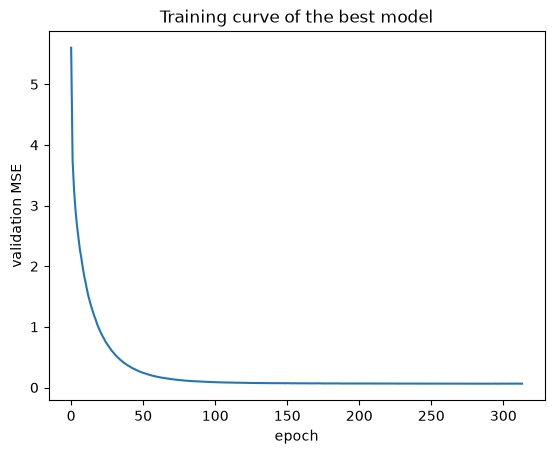

In [15]:
plt.plot(best_model.history)
plt.xlabel('epoch'); plt.ylabel('validation MSE'); plt.title('Training curve of the best model'); plt.show()

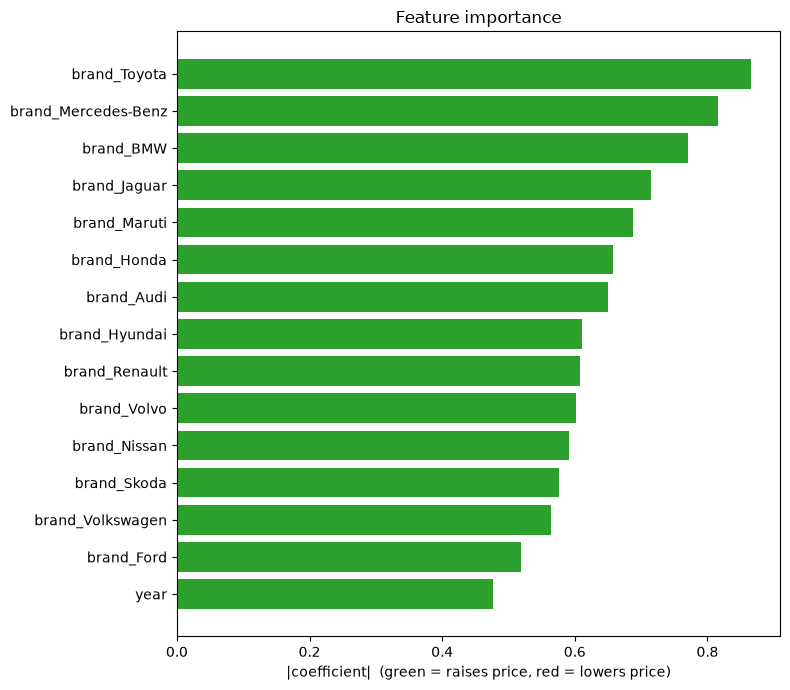

In [16]:
best_model.plot_feature_importance(feature_names, top=15)
plt.tight_layout(); plt.show()

## 7. Save the model for the web app

In [17]:
os.makedirs('models_a2', exist_ok=True)
joblib.dump(best_model, 'models_a2/car_price_model.pkl')
joblib.dump(scaler, 'models_a2/scaler.pkl')
joblib.dump({'columns': feature_names, 'num_cols': num_cols, 'cat_cols': cat_cols,
             'fill_values': fill_values, 'brands': sorted(df['brand'].unique()),
             'test_r2': float(best_model.r2(y_te, pred)),
             # the app clips inputs to these ranges, because the polynomial terms extrapolate badly
             'num_ranges': {c: (float(X_train[c].min()), float(X_train[c].max())) for c in num_cols},
             'config': {k: best[k] for k in grid}},
            'models_a2/model_columns.pkl')

with mlflow.start_run(run_name='best-model-test'):
    mlflow.log_params({k: best[k] for k in grid})
    mlflow.log_metrics({'test_mse': best_model.mse(y_te, pred), 'test_r2': best_model.r2(y_te, pred)})
    mlflow.log_artifacts('models_a2', artifact_path='model')
print(os.listdir('models_a2'))

['model_columns.pkl', 'car_price_model.pkl', 'scaler.pkl']


## 8. Report

**What the experiment shows.** 132 of the 144 runs trained without exploding. The best
configuration is **Polynomial regression, mini-batch, zero init, learning rate 0.01, no momentum**
(CV MSE 0.061, R² 0.913 on log price). On the test set it scores MSE 0.062 and R² 0.913 on log price,
slightly below A1's Random Forest (R² 0.943) but much better than plain linear regression (best
R² 0.902). The squared and interaction terms of the numeric features (e.g. `year × max_power`) let a
linear model capture some of the curvature that the forest found in A1.

**Effect of each choice.**
*Regression type:* by best run, Polynomial (0.913) > Normal (0.902) > Ridge (0.895) > Lasso (0.882).
With 6,400 rows and 40 features there is little overfitting, so the λ = 0.01 penalties of Ridge and
Lasso cost a little accuracy at the top; Lasso the most, because it pushes small brand coefficients to
exactly zero. By median run, though, Ridge and Lasso are ahead of Normal: the penalty keeps the
weights small, which makes badly-tuned runs less bad. Polynomial is
also the only type that diverged (12 runs), because its squared terms have heavy tails.
*Method:* mini-batch and stochastic reach good solutions; batch gradient descent is the most stable
(never diverged) but makes only one update per epoch, so with lr 0.001 or 0.0001 it had not converged
after 1,000 epochs (very negative R²). Stochastic updates are noisy, which helps at a small learning
rate but causes most divergences at a large one.
*Learning rate:* 0.01 is best for batch and mini-batch; stochastic works best with 0.001 or 0.0001,
because it makes thousands of updates per epoch. A rate that is
too small never converges in the epoch budget; one that is too large explodes.
*Momentum (0.9):* behaves like a ~10× larger learning rate. It rescued the slow configurations (median
R² over all runs rises from 0.76 to 0.87) but doubled the number of diverged runs, all in combinations
that were already on the edge (polynomial with a large rate).
*Init:* zeros vs Xavier makes almost no difference here. Linear regression has a single (convex)
minimum, so the start point only matters for how long it takes to get there; Xavier matters much more
for deep networks, where symmetric zero weights cannot learn.

**Feature importance.** As in A1, `year` and `max_power` dominate, now together with their squared
and interaction terms. Because the inputs are standardised, coefficient sizes are comparable.

**Limitation.** The polynomial terms extrapolate badly: one test car with more power than any training
car is predicted ten times too high, which is why R² on real prices is poor. The app clips inputs to
the training range for this model.

In [21]:
# !python app_a2.py